# Human smc: cell-type annotation (stage 04c)

Every cluster of the re-integrated smc lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_human_smc.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/human_smc.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "human", "smc", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_human_smc.h5ad"
TABLE = REPO / "resources/annotations/human_smc.csv"
PANEL = ['ACTA2', 'MYH11', 'TAGLN', 'DES', 'CNN1', 'CDH1', 'PDGFRA', 'PECAM1', 'PTPRC']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,smooth_muscle_cell,52,leiden_scVI_3.0,"ACTA2 0.77; MYH11 0.63; TAGLN 0.69; DES 0.13 | top vs lineage: SGIP1 0.85, TMSB4X 0.62, IGFBP7 0.75"
1,smooth_muscle_cell,70,leiden_scVI_3.0,"ACTA2 0.89; MYH11 0.93; TAGLN 0.59; DES 0.19 | top vs lineage: KLHL13 0.86, PCA3 0.77, STARD13 0.89"
2,smooth_muscle_cell,70,leiden_scVI_3.0,"ACTA2 0.93; MYH11 0.91; TAGLN 0.57; DES 0.27 | top vs lineage: DMD 0.96, PDLIM5 0.93, GAB1 0.89"
3,smooth_muscle_cell,50,leiden_scVI_3.0,"ACTA2 0.98; MYH11 0.84; TAGLN 0.68; DES 0.16 | top vs lineage: LPP 1.00, KCNMA1 1.00, GBE1 0.74"
4,smooth_muscle_cell,18,leiden_scVI_3.0,"ACTA2 0.83; MYH11 0.83; TAGLN 0.72; DES 0.22 | top vs lineage: PTCHD1 0.89, ACTG2 0.89, GALNT17 0.83"
5,smooth_muscle_cell,104,leiden_scVI_3.0,"ACTA2 0.89; MYH11 0.87; TAGLN 0.69; DES 0.33 | top vs lineage: PDLIM5 0.93, SORBS1 0.94, SAMD4A 0.80"
6,smooth_muscle_cell,51,leiden_scVI_3.0,"ACTA2 0.76; MYH11 0.88; TAGLN 0.61; DES 0.27 | top vs lineage: PDE4D 0.82, MAST4 0.65, HDAC9 0.69"
7,smooth_muscle_cell,30,leiden_scVI_3.0,"ACTA2 0.93; MYH11 0.83; TAGLN 0.50; DES 0.33 | top vs lineage: PCA3 0.90, PRUNE2 0.87, STAMBPL1 0.97"
8,smooth_muscle_cell,72,leiden_scVI_3.0,"ACTA2 0.87; MYH11 0.86; TAGLN 0.64; DES 0.31 | top vs lineage: SVIL 0.93, PDE10A 0.58, FGFR2 0.69"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

2084 nuclei; 45 clusters
{'smooth_muscle_cell': 2084}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

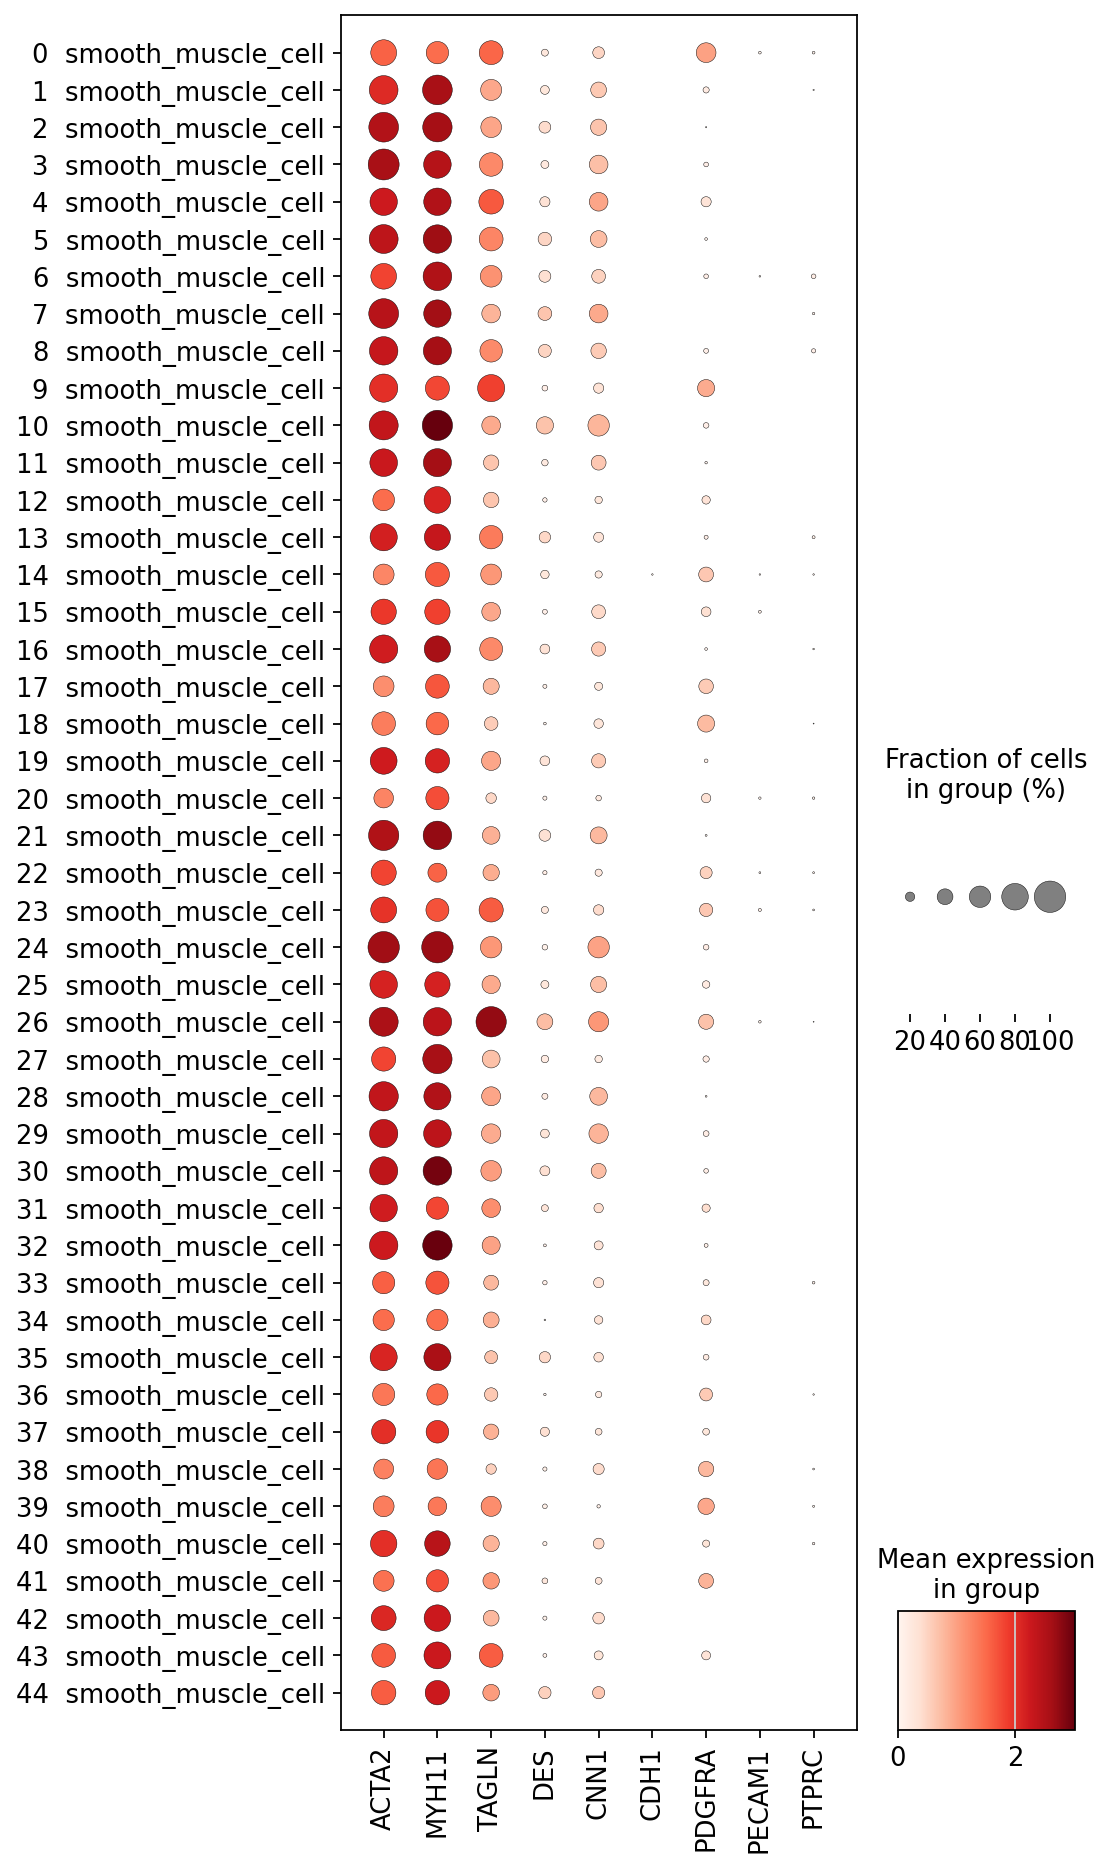

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference. A high doublet score together with markers of another lineage
(section 6) is what an EXCLUDE call rests on; a moderate score alone is not
(cycling clusters score around 1 throughout this dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,52,smooth_muscle_cell,0.07,1764.5,2974.0
1,70,smooth_muscle_cell,0.00,1722.5,3671.0
2,70,smooth_muscle_cell,0.00,1694.5,3498.0
3,50,smooth_muscle_cell,0.00,1656.0,3306.0
4,18,smooth_muscle_cell,0.00,1832.0,3766.5
5,104,smooth_muscle_cell,0.00,1698.0,3568.5
6,51,smooth_muscle_cell,0.00,1563.0,3010.0
7,30,smooth_muscle_cell,0.00,1266.5,2674.0
8,72,smooth_muscle_cell,0.00,1716.5,3533.0


## 5. UMAP by cluster and by label

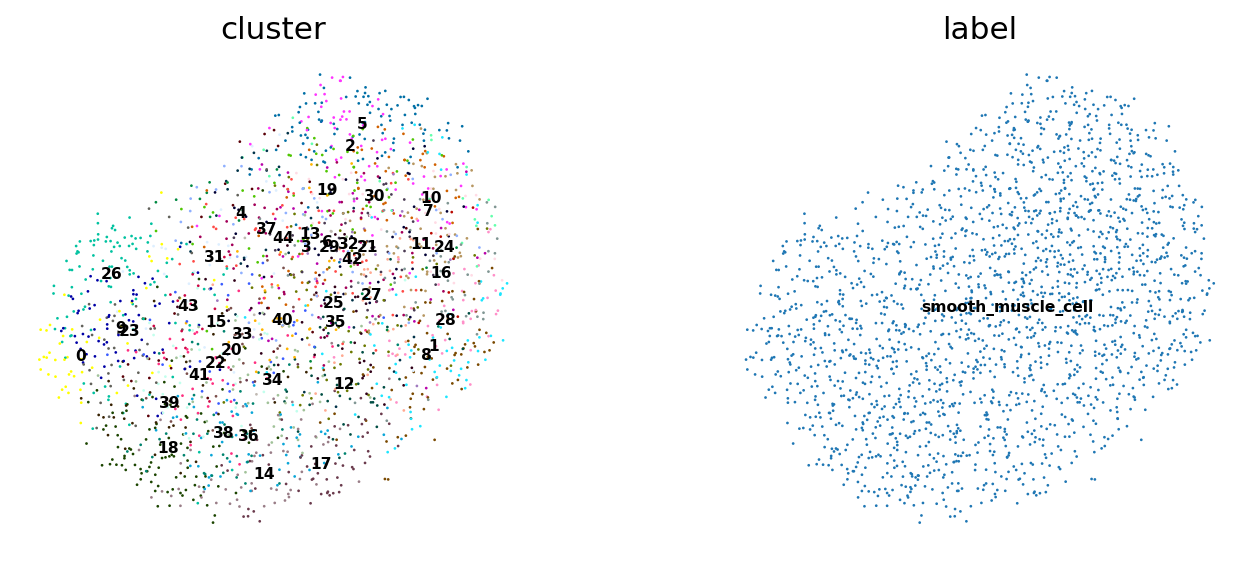

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

no EXCLUDE clusters in this table
